# ⚽ Projet 1 — Prédiction du résultat d'un match (European Soccer Database)

**Pipeline :** Data → EDA → Prétraitement → Transformation → ML → Évaluation → Déploiement (FastAPI + Docker)

**Cible :** `H` = victoire domicile, `D` = nul, `A` = victoire extérieur.

> ▶️ Exécuter : *Kernel → Restart & Run All*. Le notebook télécharge et décompresse les données tout seul.

## 0. Setup

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib kaggle fastapi uvicorn httpx requests


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, sqlite3, zipfile, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Python", sys.version.split()[0], "| dossier de travail :", os.getcwd())

Python 3.12.6 | dossier de travail : /mnt/c/Users/elkam/Documents/Bigdata


## 1. Data

In [3]:
os.makedirs("data", exist_ok=True)
DB, ZIP = "data/database.sqlite", "data/soccer.zip"

if not os.path.exists(DB):
    if not os.path.exists(ZIP) or os.path.getsize(ZIP) < 30e6:
        try:
            subprocess.run(["kaggle", "datasets", "download", "-d", "hugomathien/soccer", "-p", "data"], check=False)
        except FileNotFoundError:
            print("CLI kaggle introuvable.")
    if os.path.exists(ZIP) and os.path.getsize(ZIP) > 30e6:
        zipfile.ZipFile(ZIP).extractall("data")
    else:
        raise SystemExit("❌ Télécharge soccer.zip à la main sur https://www.kaggle.com/datasets/hugomathien/soccer "
                         "et place-le dans le dossier data/, puis relance cette cellule.")
print("✅ Base prête :", DB, f"({os.path.getsize(DB)/1e6:.0f} Mo)")

Dataset URL: https://www.kaggle.com/datasets/hugomathien/soccer
License(s): ODbL-1.0


100%|██████████| 32.7M/32.7M [00:02<00:00, 14.0MB/s]
[Errno 1] Operation not permitted




Connection error: PermissionError: [Errno 1] Operation not permitted
Retrying in 2.7 seconds... (attempt 1/5)

Connection error: PermissionError: [Errno 1] Operation not permitted
Retrying in 5.0 seconds... (attempt 2/5)

Connection error: PermissionError: [Errno 1] Operation not permitted
Retrying in 8.1 seconds... (attempt 3/5)

Connection error: PermissionError: [Errno 1] Operation not permitted
Retrying in 16.4 seconds... (attempt 4/5)

Connection error: PermissionError: [Errno 1] Operation not permitted
Retrying in 32.3 seconds... (attempt 5/5)

Download failed after 5 retries.
Error: PermissionError: [Errno 1] Operation not permitted
Partial file saved at: data/soccer.zip
You can resume by running the same command again.
✅ Base prête : data/database.sqlite (313 Mo)


In [4]:
conn = sqlite3.connect(DB)
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)

,name
0,sqlite_sequence
1,Player_Attributes
2,Player
3,Match
4,League
5,Country
6,Team
7,Team_Attributes


In [5]:
match = pd.read_sql('''
    SELECT m.match_api_id, m.season, m.stage, m.date,
           m.home_team_api_id, m.away_team_api_id,
           m.home_team_goal, m.away_team_goal,
           m.B365H, m.B365D, m.B365A,
           l.name AS league
    FROM Match m JOIN League l ON m.league_id = l.id
''', conn)
team_attr = pd.read_sql("SELECT * FROM Team_Attributes", conn)

match["date"] = pd.to_datetime(match["date"])
match["result"] = np.select(
    [match.home_team_goal > match.away_team_goal,
     match.home_team_goal < match.away_team_goal],
    ["H", "A"], default="D")
print(match.shape, team_attr.shape)
match.head()

(25979, 13) (1458, 25)


,match_api_id,season,stage,date,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,B365H,B365D,B365A,league,result
0,492473,2008/2009,1,2008-08-17,9987,9993,1,1,1.73,3.40,5.00,Belgium Jupiler League,D
1,492474,2008/2009,1,2008-08-16,10000,9994,0,0,1.95,3.20,3.60,Belgium Jupiler League,D
2,492475,2008/2009,1,2008-08-16,9984,8635,0,3,2.38,3.30,2.75,Belgium Jupiler League,A
3,492476,2008/2009,1,2008-08-17,9991,9998,5,0,1.44,3.75,7.50,Belgium Jupiler League,H
4,492477,2008/2009,1,2008-08-16,7947,9985,1,3,5.00,3.50,1.65,Belgium Jupiler League,A


## 2. EDA (analyse exploratoire)

In [6]:
match.info()
display(match.describe().T)
display(match.isna().mean().sort_values(ascending=False).head(10).to_frame("taux_NaN"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25979 entries, 0 to 25978
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   match_api_id      25979 non-null  int64         
 1   season            25979 non-null  object        
 2   stage             25979 non-null  int64         
 3   date              25979 non-null  datetime64[ns]
 4   home_team_api_id  25979 non-null  int64         
 5   away_team_api_id  25979 non-null  int64         
 6   home_team_goal    25979 non-null  int64         
 7   away_team_goal    25979 non-null  int64         
 8   B365H             22592 non-null  float64       
 9   B365D             22592 non-null  float64       
 10  B365A             22592 non-null  float64       
 11  league            25979 non-null  object        
 12  result            25979 non-null  object        
dtypes: datetime64[ns](1), float64(3), int64(6), object(3)
memory usage: 2.6+ MB


,count,mean,min,25%,50%,75%,max,std
match_api_id,25979.0,1195429.159975,483129.0,768436.5,1147511.0,1709852.5,2216672.0,494627.856527
stage,25979.0,18.242773,1.0,9.0,18.0,27.0,38.0,10.407354
date,25979,2012-06-30 17:53:53.334616320,2008-07-18 00:00:00,2010-05-09 00:00:00,2012-05-13 00:00:00,2014-08-17 00:00:00,2016-05-25 00:00:00,NaN
home_team_api_id,25979.0,9984.371993,1601.0,8475.0,8697.0,9925.0,274581.0,14087.453758
away_team_api_id,25979.0,9984.475115,1601.0,8475.0,8697.0,9925.0,274581.0,14087.445135
home_team_goal,25979.0,1.544594,0.0,1.0,1.0,2.0,10.0,1.297158
away_team_goal,25979.0,1.160938,0.0,0.0,1.0,2.0,9.0,1.14211
B365H,22592.0,2.628818,1.04,1.67,2.1,2.8,26.0,1.794463
B365D,22592.0,3.839684,1.4,3.3,3.5,4.0,17.0,1.118269
B365A,22592.0,4.662222,1.08,2.5,3.5,5.25,51.0,3.730104


,taux_NaN
B365H,0.130375
B365D,0.130375
B365A,0.130375
season,0.000000
match_api_id,0.000000
home_team_api_id,0.000000
date,0.000000
stage,0.000000
away_team_api_id,0.000000
away_team_goal,0.000000


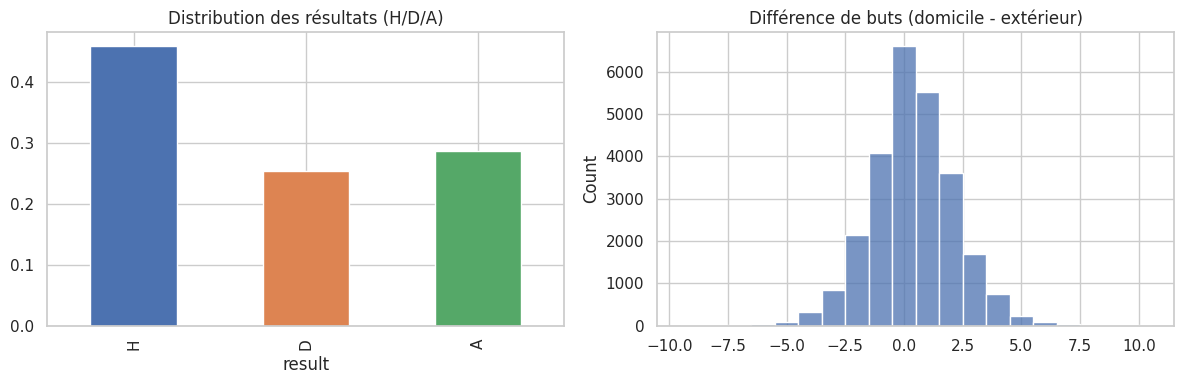

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
match["result"].value_counts(normalize=True).reindex(["H", "D", "A"]).plot.bar(
    ax=ax[0], color=["#4C72B0", "#DD8452", "#55A868"])
ax[0].set_title("Distribution des résultats (H/D/A)")
sns.histplot(match.home_team_goal - match.away_team_goal, discrete=True, ax=ax[1])
ax[1].set_title("Différence de buts (domicile - extérieur)")
plt.tight_layout(); plt.show()

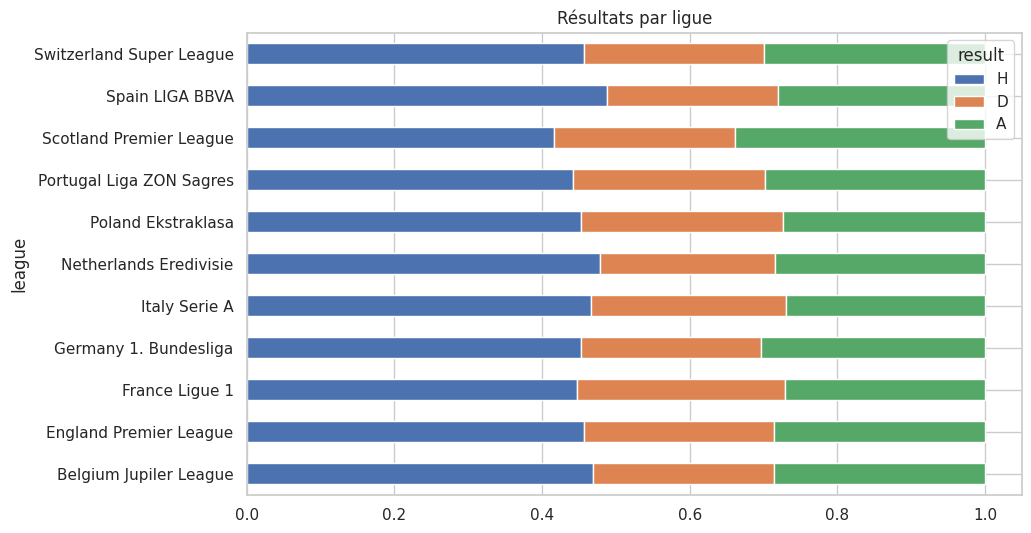

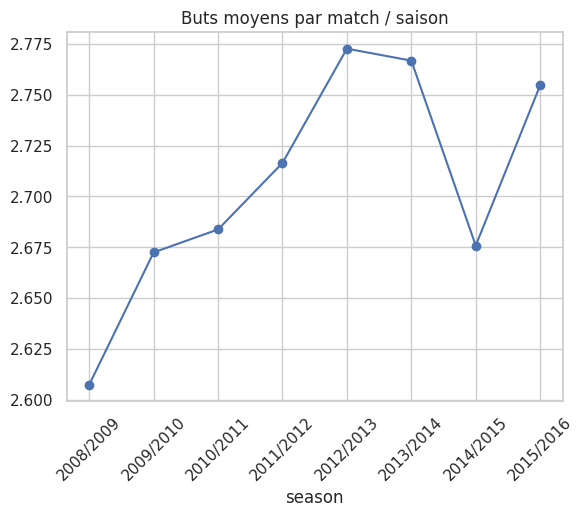

In [8]:
pd.crosstab(match.league, match.result, normalize="index")[["H", "D", "A"]].plot.barh(
    stacked=True, figsize=(10, 6), title="Résultats par ligue"); plt.show()

match.assign(goals=match.home_team_goal + match.away_team_goal) \
     .groupby("season")["goals"].mean().plot(marker="o", title="Buts moyens par match / saison")
plt.xticks(rotation=45); plt.show()

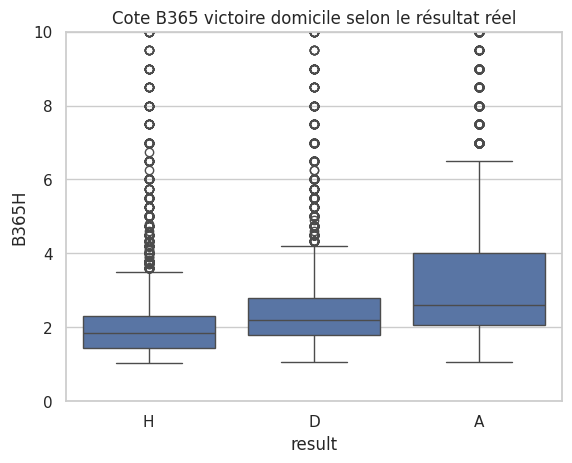

In [9]:
sns.boxplot(data=match, x="result", y="B365H", order=["H", "D", "A"])
plt.ylim(0, 10); plt.title("Cote B365 victoire domicile selon le résultat réel"); plt.show()

**Constats :** ~46 % de victoires à domicile (avantage du terrain), ~25 % de nuls ; les cotes sont très liées au résultat ; ~13 % des matchs n'ont pas de cotes.

## 3. Prétraitement

In [10]:
print("Avant :", match.shape)
match = match.dropna(subset=["B365H", "B365D", "B365A"])
match = match.drop_duplicates("match_api_id").sort_values("date").reset_index(drop=True)
print("Après :", match.shape)

Avant : (25979, 13)
Après : (22592, 13)


In [11]:
ATTR = ["buildUpPlaySpeed", "buildUpPlayPassing", "chanceCreationPassing",
        "chanceCreationCrossing", "chanceCreationShooting",
        "defencePressure", "defenceAggression", "defenceTeamWidth"]

ta = team_attr[["team_api_id", "date"] + ATTR].copy()
ta["date"] = pd.to_datetime(ta["date"])
ta = ta.sort_values("date")

def add_team_attr(df, side):
    tmp = ta.rename(columns={"team_api_id": f"{side}_team_api_id",
                             **{c: f"{side}_{c}" for c in ATTR}})
    return pd.merge_asof(df.sort_values("date"), tmp, on="date",
                         by=f"{side}_team_api_id", direction="backward")

match = add_team_attr(match, "home")
match = add_team_attr(match, "away")
match.filter(like="_buildUpPlaySpeed").isna().mean()

home_buildUpPlaySpeed    0.232516
away_buildUpPlaySpeed    0.232339
dtype: float64

## 4. Transformation / Feature engineering

In [12]:
home = match[["match_api_id", "date", "home_team_api_id", "home_team_goal", "away_team_goal"]] \
        .rename(columns={"home_team_api_id": "team", "home_team_goal": "gf", "away_team_goal": "ga"})
away = match[["match_api_id", "date", "away_team_api_id", "away_team_goal", "home_team_goal"]] \
        .rename(columns={"away_team_api_id": "team", "away_team_goal": "gf", "home_team_goal": "ga"})
long = pd.concat([home, away]).sort_values(["team", "date"])
long["pts"] = np.select([long.gf > long.ga, long.gf == long.ga], [3, 1], 0)

for c in ["gf", "ga", "pts"]:
    long[f"{c}5"] = long.groupby("team")[c].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean())

form = long[["match_api_id", "team", "gf5", "ga5", "pts5"]]
for side in ["home", "away"]:
    match = match.merge(
        form.rename(columns={"team": f"{side}_team_api_id", "gf5": f"{side}_gf5",
                             "ga5": f"{side}_ga5", "pts5": f"{side}_pts5"}),
        on=["match_api_id", f"{side}_team_api_id"], how="left")
match[["home_gf5", "home_pts5", "away_gf5", "away_pts5"]].describe()

,home_gf5,home_pts5,away_gf5,away_pts5
count,22467.000000,22467.000000,22457.000000,22457.000000
mean,1.336704,1.347846,1.375482,1.402907
std,0.650707,0.677369,0.663555,0.681384
min,0.000000,0.000000,0.000000,0.000000
25%,0.800000,0.800000,1.000000,0.800000
50%,1.200000,1.400000,1.200000,1.400000
75%,1.600000,1.800000,1.800000,1.800000
max,5.800000,3.000000,5.000000,3.000000


In [13]:
inv = 1 / match[["B365H", "B365D", "B365A"]]
inv = inv.div(inv.sum(axis=1), axis=0)
match[["p_home", "p_draw", "p_away"]] = inv.values
match[["p_home", "p_draw", "p_away"]].describe()

,p_home,p_draw,p_away
count,22592.000000,22592.000000,22592.000000
mean,0.450510,0.257833,0.291657
std,0.174227,0.046544,0.155738
min,0.036446,0.056034,0.019043
25%,0.336356,0.240000,0.179153
50%,0.446512,0.272727,0.268698
75%,0.562008,0.287793,0.375000
max,0.920351,0.655095,0.877408


Train : (19687, 27) | Test : (2905, 27)


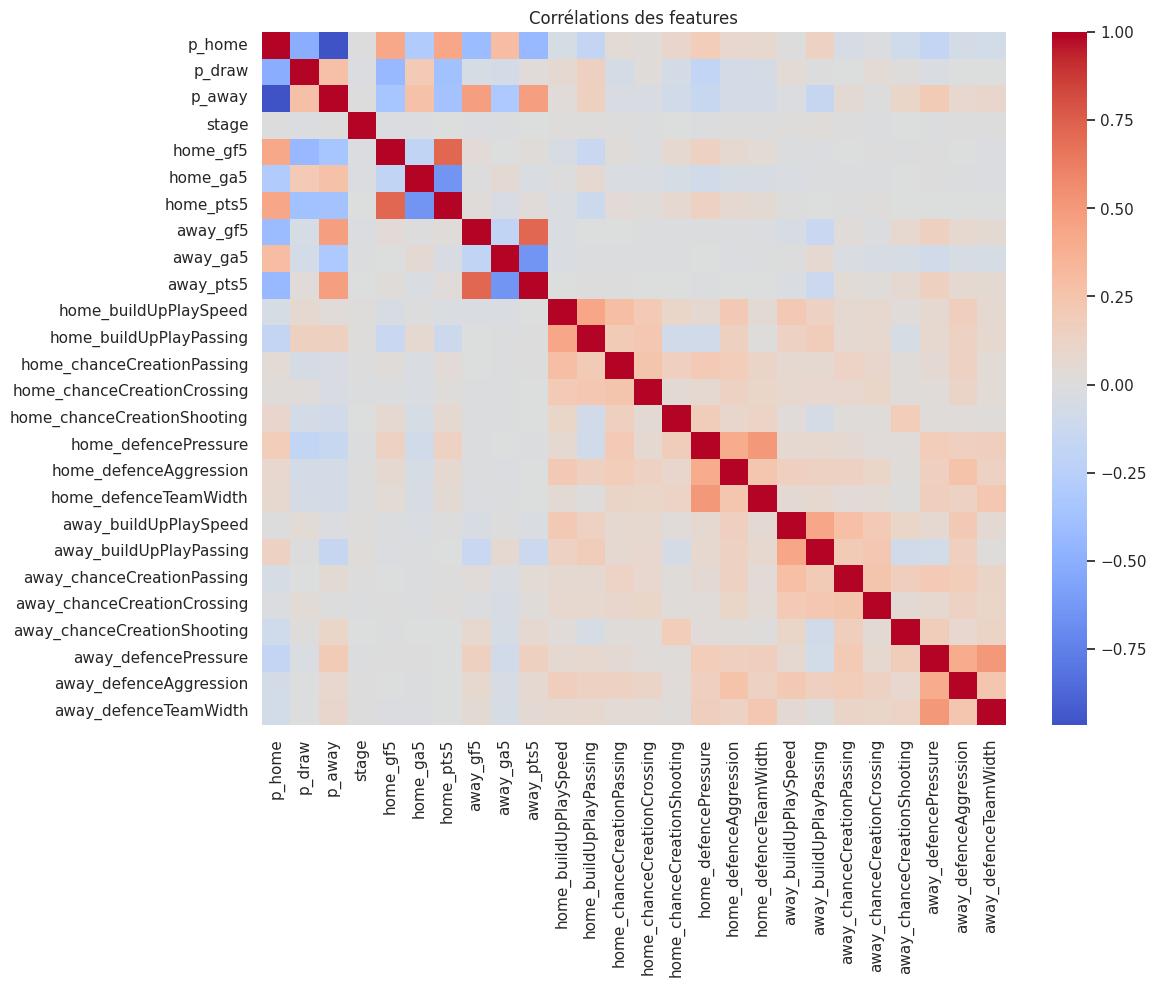

In [14]:
NUM = (["p_home", "p_draw", "p_away", "stage"]
       + [f"{s}_{c}" for s in ["home", "away"] for c in ["gf5", "ga5", "pts5"]]
       + [f"{s}_{c}" for s in ["home", "away"] for c in ATTR])
CAT = ["league"]
TARGET = "result"

# Split TEMPOREL : dernière saison = test
test_mask = match.season == "2015/2016"
X_train, y_train = match.loc[~test_mask, NUM + CAT], match.loc[~test_mask, TARGET]
X_test,  y_test  = match.loc[test_mask,  NUM + CAT], match.loc[test_mask,  TARGET]
print("Train :", X_train.shape, "| Test :", X_test.shape)

plt.figure(figsize=(12, 9))
sns.heatmap(match[NUM].corr(), cmap="coolwarm", center=0)
plt.title("Corrélations des features"); plt.show()

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])

## 5. Machine Learning

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

models = {
    "LogReg": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "HistGB": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
results, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)]).fit(X_train, y_train)
    proba, pred = pipe.predict_proba(X_test), pipe.predict(X_test)
    results.append({"modèle": name,
                    "accuracy": accuracy_score(y_test, pred),
                    "f1_macro": f1_score(y_test, pred, average="macro"),
                    "log_loss": log_loss(y_test, proba, labels=pipe.classes_)})
    fitted[name] = pipe

# Baseline : le résultat jugé le plus probable par le bookmaker
bk_pred = np.array(["H", "D", "A"])[X_test[["p_home", "p_draw", "p_away"]].values.argmax(1)]
results.append({"modèle": "Bookmaker (baseline)",
                "accuracy": accuracy_score(y_test, bk_pred),
                "f1_macro": f1_score(y_test, bk_pred, average="macro"), "log_loss": np.nan})
res = pd.DataFrame(results).sort_values("log_loss")
res

,modèle,accuracy,f1_macro,log_loss
0,LogReg,0.519105,0.385387,0.979835
1,RandomForest,0.521170,0.383776,0.980607
2,HistGB,0.515318,0.395951,0.988980
3,Bookmaker (baseline),0.520138,0.379923,NaN


In [17]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

pipe = Pipeline([("prep", preprocess),
                 ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
grid = {"model__learning_rate": [0.03, 0.1],
        "model__max_depth": [3, 6],
        "model__max_iter": [200],
        "model__l2_regularization": [0.0, 1.0]}
gs = GridSearchCV(pipe, grid, cv=TimeSeriesSplit(n_splits=4),
                  scoring="neg_log_loss", n_jobs=-1, verbose=1)
gs.fit(X_train, y_train)
print("Meilleurs params :", gs.best_params_)
print("CV log_loss :", round(-gs.best_score_, 4))
best = gs.best_estimator_

Fitting 4 folds for each of 8 candidates, totalling 32 fits
Meilleurs params : {'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 200}
CV log_loss : 0.9784


## 6. Évaluation

              precision    recall  f1-score   support

           A      0.499     0.479     0.489       884
           D      0.000     0.000     0.000       733
           H      0.526     0.839     0.646      1288

    accuracy                          0.517      2905
   macro avg      0.342     0.439     0.378      2905
weighted avg      0.385     0.517     0.435      2905

Accuracy test : 0.5174
Log loss test : 0.9814


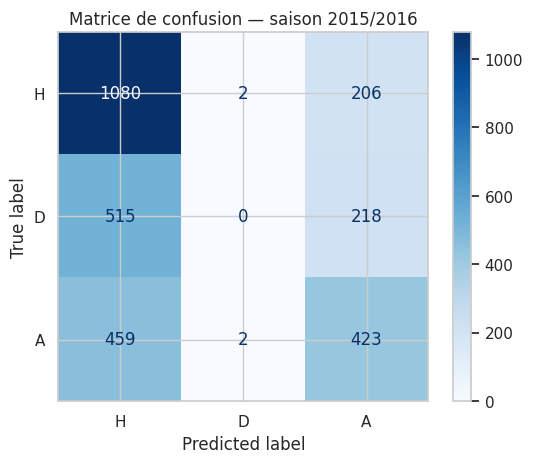

In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = best.predict(X_test)
print(classification_report(y_test, pred, digits=3))
print("Accuracy test :", round(accuracy_score(y_test, pred), 4))
print("Log loss test :", round(log_loss(y_test, best.predict_proba(X_test), labels=best.classes_), 4))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, labels=["H", "D", "A"], cmap="Blues")
plt.title("Matrice de confusion — saison 2015/2016"); plt.show()

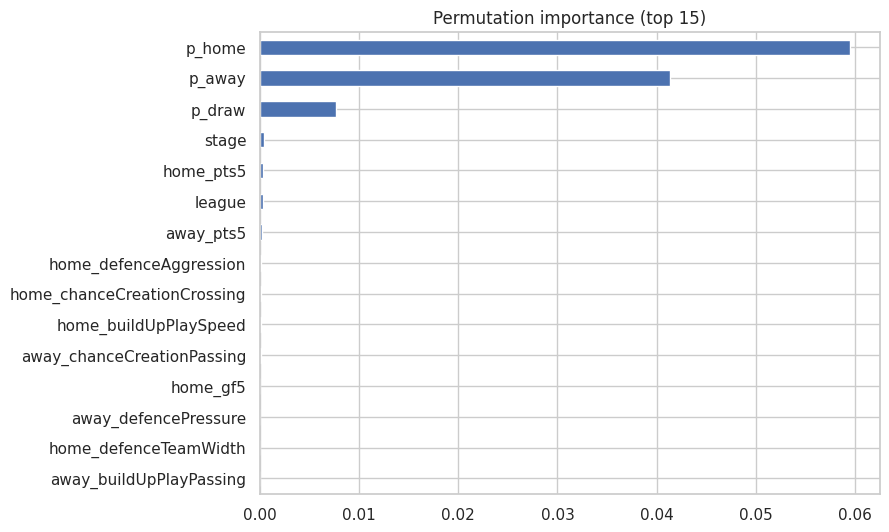

In [19]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(best, X_test, y_test, n_repeats=5,
                            random_state=RANDOM_STATE, scoring="neg_log_loss", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(15).plot.barh(figsize=(8, 6), title="Permutation importance (top 15)"); plt.show()

**Conclusion :** le modèle atteint une accuracy proche de celle des bookmakers (~50–53 %), ce qui est le niveau attendu sur ce problème.
Les probabilités implicites des cotes sont les variables les plus informatives, suivies de la forme récente.
Le match nul reste quasi impossible à prédire (rappel faible sur `D`).

## 7. Déploiement — API FastAPI + Docker

In [20]:
import joblib, sklearn
os.makedirs("models", exist_ok=True)
os.makedirs("app", exist_ok=True)
open("app/__init__.py", "w").close()

joblib.dump(best, "models/model.joblib")
json.dump({"num": NUM, "cat": CAT}, open("models/features.json", "w"))

with open("requirements.txt", "w") as f:
    f.write("fastapi\nuvicorn[standard]\njoblib\n"
            f"scikit-learn=={sklearn.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\n")
print(open("requirements.txt").read())

fastapi
uvicorn[standard]
joblib
scikit-learn==1.8.0
pandas==2.3.3
numpy==2.3.5



In [21]:
%%writefile app/main.py
import json
from typing import Optional
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import create_model

model = joblib.load("models/model.joblib")
FEAT = json.load(open("models/features.json"))

MatchIn = create_model("MatchIn", league=(str, ...),
                       **{f: (Optional[float], None) for f in FEAT["num"]})

app = FastAPI(title="Soccer Result Predictor")

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/predict")
def predict(match: MatchIn):
    df = pd.DataFrame([match.model_dump()])
    df[FEAT["num"]] = df[FEAT["num"]].astype(float)   # None -> NaN (imputé par le pipeline)
    proba = model.predict_proba(df[FEAT["num"] + FEAT["cat"]])[0]
    return {"prediction": str(model.classes_[proba.argmax()]),
            "probabilities": {str(k): float(v) for k, v in zip(model.classes_, proba.round(4))}}

Writing app/main.py


In [22]:
py = f"{sys.version_info.major}.{sys.version_info.minor}"
with open("Dockerfile", "w") as f:
    f.write(f'''FROM python:{py}-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app/ app/
COPY models/ models/
EXPOSE 8000
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]
''')
with open(".dockerignore", "w") as f:
    f.write("data/\n*.ipynb\n.ipynb_checkpoints/\n__pycache__/\n")
print(open("Dockerfile").read())

FROM python:3.12-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app/ app/
COPY models/ models/
EXPOSE 8000
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]



In [23]:
import importlib, app.main as api
importlib.reload(api)
from fastapi.testclient import TestClient
client = TestClient(api.app)

def to_payload(row):
    return {k: (None if pd.isna(v) else (v if k == "league" else float(v))) for k, v in row.items()}

payload = to_payload(X_test.iloc[0])
print("health :", client.get("/health").json())
print("Vrai résultat :", y_test.iloc[0], "| API :", client.post("/predict", json=payload).json())

health : {'status': 'ok'}
Vrai résultat : H | API : {'prediction': 'A', 'probabilities': {'A': 0.5309, 'D': 0.2667, 'H': 0.2024}}


In [24]:
import shutil, time, requests
if shutil.which("docker"):
    subprocess.run("docker rm -f soccer-api", shell=True, capture_output=True)
    b = subprocess.run("docker build -t soccer-api .", shell=True)
    if b.returncode == 0:
        subprocess.run("docker run -d --name soccer-api -p 8000:8000 soccer-api", shell=True)
        time.sleep(8)
        r = requests.post("http://localhost:8000/predict", json=payload)
        print("Réponse du conteneur :", r.json())
        print("👉 Swagger : http://localhost:8000/docs")
else:
    print("Docker non détecté : installe Docker Desktop puis relance cette cellule.\n"
          "Commandes manuelles : docker build -t soccer-api .  &&  docker run -d -p 8000:8000 soccer-api")

#0 building with "default" instance using docker driver

#1 [internal] load build definition from Dockerfile
#1 transferring dockerfile: 268B 0.0s done
#1 DONE 0.1s

#2 [internal] load metadata for docker.io/library/python:3.12-slim
#2 DONE 0.7s

#3 [internal] load .dockerignore
#3 transferring context: 87B 0.0s done
#3 DONE 0.1s

#4 [1/6] FROM docker.io/library/python:3.12-slim@sha256:5e2bdb1b0d542d5039cffb8181c65930093949194a65c365dfb1b0fe13a4fa5b
#4 DONE 0.0s

#5 [internal] load build context
#5 transferring context: 308.37kB 0.1s done
#5 DONE 0.1s

#6 [2/6] WORKDIR /app
#6 CACHED

#7 [3/6] COPY requirements.txt .
#7 CACHED

#8 [4/6] RUN pip install --no-cache-dir -r requirements.txt
#8 CACHED

#9 [5/6] COPY app/ app/
#9 DONE 0.1s

#10 [6/6] COPY models/ models/
#10 DONE 0.1s

#11 exporting to image
#11 exporting layers 0.1s done
#11 writing image sha256:2604b72f200b9e153bb64bb2c54819eed5e440734760585f5fa92a69600704e1 done
#11 naming to docker.io/library/soccer-api done
#11 DONE 0.1

9148cf4640f3a93dfff5d7989acde838a3820d6642349448a49b6a2208b0e072
Réponse du conteneur : {'prediction': 'A', 'probabilities': {'A': 0.5309, 'D': 0.2667, 'H': 0.2024}}
👉 Swagger : http://localhost:8000/docs
